<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 26: Gibbs Sampling and Contrastive Divergence Analysis

**Category**: CO5 – Energy-Based and Generative Models  
**Objective**: Simulate Markov Chain Monte Carlo Gibbs sampling to drive Contrastive Divergence parameter estimation in energy-based models.


### Task 1: Contrastive Divergence (CD-k) with Gibbs Sampling Markov Chain


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
n_vis, n_hid = 12, 6

W = np.random.randn(n_vis, n_hid) * 0.2
b_vis = np.zeros(n_vis)
b_hid = np.zeros(n_hid)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -15, 15)))

def gibbs_step(v):
    # Sample h ~ P(h | v)
    p_h = sigmoid(np.dot(v, W) + b_hid)
    h = (np.random.rand(*p_h.shape) < p_h).astype(float)
    # Sample v ~ P(v | h)
    p_v = sigmoid(np.dot(h, W.T) + b_vis)
    v_next = (np.random.rand(*p_v.shape) < p_v).astype(float)
    return h, v_next

# Run Gibbs sampling trajectory for 10 steps
initial_v = (np.random.rand(1, n_vis) < 0.5).astype(float)
chain_trajectory = [initial_v[0].copy()]

curr_v = initial_v
for step in range(1, 11):
    _, curr_v = gibbs_step(curr_v)
    chain_trajectory.append(curr_v[0].copy())

chain_matrix = np.array(chain_trajectory)
print("Gibbs Sampling Trajectory Array Shape (11 Steps x 12 Units):", chain_matrix.shape)


Gibbs Sampling Trajectory Array Shape (11 Steps x 12 Units): (11, 12)


### Task 2: Visualize Markov Chain State Transitions Heatmap


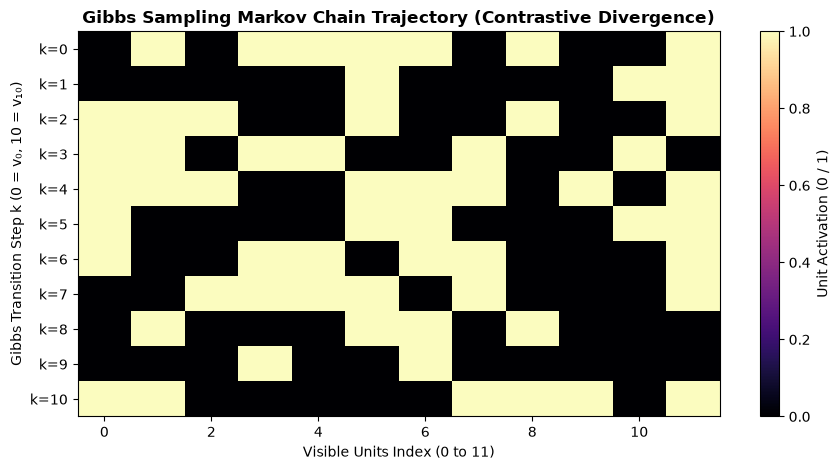

In [2]:
plt.figure(figsize=(9, 4.8))
plt.imshow(chain_matrix, cmap='magma', aspect='auto', interpolation='nearest')
plt.colorbar(label='Unit Activation (0 / 1)')
plt.title("Gibbs Sampling Markov Chain Trajectory (Contrastive Divergence)", fontweight='bold')
plt.xlabel("Visible Units Index (0 to 11)")
plt.ylabel("Gibbs Transition Step k (0 = v₀, 10 = v₁₀)")
plt.yticks(range(11), [f"k={k}" for k in range(11)])
plt.tight_layout()
plt.show()
